# Apple Leaf Binary Image Classification
## CNN Model Experiment

### Objective
The objective of this experiment is to investigate the performance
of a Convolutional Neural Network (CNN) for binary classification
of apple leaf images.

### Classes
- Healthy Leaf
- Unhealthy Leaf

### Model
A custom CNN developed using TensorFlow and Keras.

### Image Size
128 × 128 × 3

### Output
Binary classification using a sigmoid activation function.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.utils import load_img, img_to_array

In [2]:
PROJECT_ROOT = Path.cwd()

MODEL_PATH = PROJECT_ROOT / "models" / "best_leaf_classifier.keras"
TEST_DIR = PROJECT_ROOT / "dataset" / "split" / "test"

IMAGE_SIZE = (128, 128)
CLASS_NAMES = ["Healthy_leaf", "Unhealthy_leaf"]

model = tf.keras.models.load_model(MODEL_PATH)

print("Model loaded successfully!")

Model loaded successfully!


In [3]:
model.summary()

Model: "leaf_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 329,669 (1.26 MB)

 Trainable params: 109,889 (429.25 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 219,780 (858.52 KB)

In [4]:
healthy_images = list((TEST_DIR / "Healthy_leaf").glob("*"))
unhealthy_images = list((TEST_DIR / "Unhealthy_leaf").glob("*"))

print("Healthy images:", len(healthy_images))
print("Unhealthy images:", len(unhealthy_images))

healthy_image = healthy_images[0]
unhealthy_image = unhealthy_images[0]

print("\nSelected images:")
print("Healthy:", healthy_image.name)
print("Unhealthy:", unhealthy_image.name)

Healthy images: 45
Unhealthy images: 45

Selected images:
Healthy: d1660af9-58e5-458f-b125-4940f06711c0___RS_HL 7522.JPG
Unhealthy: 77f413dd-06cd-4e01-92f9-fdb8d0320b68___FREC_C.Rust 0089.JPG


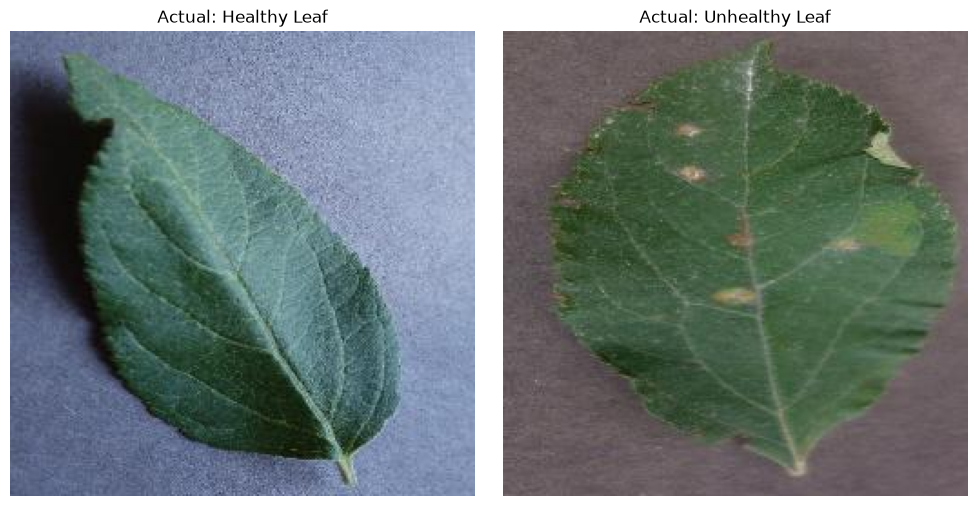

In [5]:
plt.figure(figsize=(10, 5))

# Healthy image
plt.subplot(1, 2, 1)
plt.imshow(load_img(healthy_image))
plt.title("Actual: Healthy Leaf")
plt.axis("off")

# Unhealthy image
plt.subplot(1, 2, 2)
plt.imshow(load_img(unhealthy_image))
plt.title("Actual: Unhealthy Leaf")
plt.axis("off")

plt.tight_layout()
plt.show()

In [6]:
def predict_image(image_path):

    # Load and resize image
    image = load_img(
        image_path,
        target_size=IMAGE_SIZE
    )

    # Convert image into numerical array
    image_array = img_to_array(image)

    # Add batch dimension
    image_array = np.expand_dims(image_array, axis=0)

    # Predict using CNN
    probability = model.predict(image_array, verbose=0)[0][0]

    # Determine predicted class
    if probability >= 0.5:
        predicted_class = "Unhealthy_leaf"
    else:
        predicted_class = "Healthy_leaf"

    return predicted_class, probability

In [7]:
healthy_prediction, healthy_probability = predict_image(healthy_image)
unhealthy_prediction, unhealthy_probability = predict_image(unhealthy_image)

print("HEALTHY IMAGE")
print("Actual class: Healthy_leaf")
print("Predicted class:", healthy_prediction)
print(f"Unhealthy probability: {healthy_probability:.4f}")

print("\nUNHEALTHY IMAGE")
print("Actual class: Unhealthy_leaf")
print("Predicted class:", unhealthy_prediction)
print(f"Unhealthy probability: {unhealthy_probability:.4f}")

HEALTHY IMAGE
Actual class: Healthy_leaf
Predicted class: Healthy_leaf
Unhealthy probability: 0.0608

UNHEALTHY IMAGE
Actual class: Unhealthy_leaf
Predicted class: Unhealthy_leaf
Unhealthy probability: 0.8609


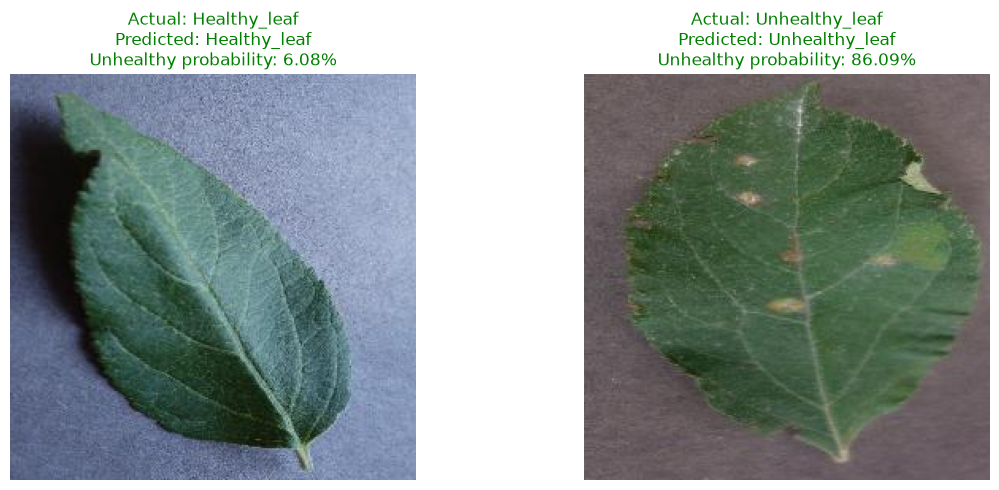

In [8]:
sample_images = [
    (healthy_image, "Healthy_leaf"),
    (unhealthy_image, "Unhealthy_leaf")
]

plt.figure(figsize=(12, 5))

for index, (image_path, actual_class) in enumerate(sample_images):

    predicted_class, probability = predict_image(image_path)

    plt.subplot(1, 2, index + 1)
    plt.imshow(load_img(image_path))

    color = "green" if predicted_class == actual_class else "red"

    plt.title(
        f"Actual: {actual_class}\n"
        f"Predicted: {predicted_class}\n"
        f"Unhealthy probability: {probability:.2%}",
        color=color
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

# Testing multiple images

In [9]:
print("MULTIPLE IMAGE EXPERIMENT")
print("-" * 50)

for actual_class, image_list in [
    ("Healthy_leaf", healthy_images[:10]),
    ("Unhealthy_leaf", unhealthy_images[:10])
]:

    correct = 0

    for image_path in image_list:

        predicted_class, probability = predict_image(image_path)

        is_correct = predicted_class == actual_class

        if is_correct:
            correct += 1

        print(
            f"Actual: {actual_class:15} | "
            f"Predicted: {predicted_class:15} | "
            f"Correct: {is_correct}"
        )

    print(f"\nAccuracy for {actual_class}: {correct}/10")
    print("-" * 50)

MULTIPLE IMAGE EXPERIMENT
--------------------------------------------------
Actual: Healthy_leaf    | Predicted: Healthy_leaf    | Correct: True
Actual: Healthy_leaf    | Predicted: Unhealthy_leaf  | Correct: False
Actual: Healthy_leaf    | Predicted: Healthy_leaf    | Correct: True
Actual: Healthy_leaf    | Predicted: Unhealthy_leaf  | Correct: False
Actual: Healthy_leaf    | Predicted: Unhealthy_leaf  | Correct: False
Actual: Healthy_leaf    | Predicted: Healthy_leaf    | Correct: True
Actual: Healthy_leaf    | Predicted: Unhealthy_leaf  | Correct: False
Actual: Healthy_leaf    | Predicted: Unhealthy_leaf  | Correct: False
Actual: Healthy_leaf    | Predicted: Healthy_leaf    | Correct: True
Actual: Healthy_leaf    | Predicted: Healthy_leaf    | Correct: True

Accuracy for Healthy_leaf: 5/10
--------------------------------------------------
Actual: Unhealthy_leaf  | Predicted: Unhealthy_leaf  | Correct: True
Actual: Unhealthy_leaf  | Predicted: Unhealthy_leaf  | Correct: True
Actual

In [11]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import seaborn as sns

all_images = healthy_images + unhealthy_images

actual_labels = (
    ["Healthy_leaf"] * len(healthy_images)
    + ["Unhealthy_leaf"] * len(unhealthy_images)
)

predicted_labels = []
prediction_scores = []

for image_path in all_images:

    predicted_class, probability = predict_image(image_path)

    predicted_labels.append(predicted_class)
    prediction_scores.append(probability)

print("Total images evaluated:", len(all_images))
print("Predictions completed!")

Total images evaluated: 90
Predictions completed!


In [12]:
accuracy = accuracy_score(actual_labels, predicted_labels)

print(f"Test Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:\n")

print(
    classification_report(
        actual_labels,
        predicted_labels,
        target_names=["Healthy", "Unhealthy"]
    )
)

Test Accuracy: 85.56%

Classification Report:

              precision    recall  f1-score   support

     Healthy       1.00      0.71      0.83        45
   Unhealthy       0.78      1.00      0.87        45

    accuracy                           0.86        90
   macro avg       0.89      0.86      0.85        90
weighted avg       0.89      0.86      0.85        90



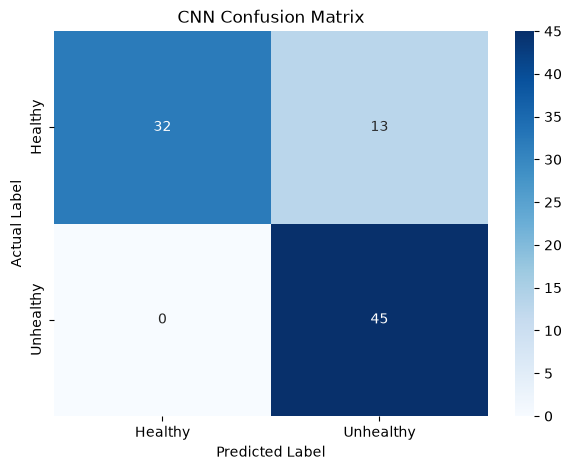

In [13]:
cm = confusion_matrix(
    actual_labels,
    predicted_labels,
    labels=CLASS_NAMES
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Healthy", "Unhealthy"],
    yticklabels=["Healthy", "Unhealthy"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("CNN Confusion Matrix")

plt.show()

## Experiment Conclusion

A custom Convolutional Neural Network (CNN) was developed
to classify apple leaf images into two categories:
Healthy and Unhealthy.

The trained model was evaluated using 90 previously unseen
test images.

The experiment investigated:
- CNN architecture and trainable parameters.
- Image preprocessing and prediction.
- Binary classification using sigmoid activation.
- Classification accuracy, precision, recall, and F1-score.
- Confusion matrix and classification errors.

The results provide an initial assessment of the model's
ability to distinguish between the two image classes.

Further experiments with larger and more diverse datasets
are necessary to evaluate its generalization ability.